# Project Analisis Sentimen Aplikasi Simobiplus
Proyek ini membandingkan tiga arsitektur model (SVM, Bi-LSTM, dan IndoBERT) untuk mengklasifikasikan sentimen ulasan pengguna ke dalam kategori Negatif, Netral, dan Positif.

## 1. Import Library dan Persiapan Environment
Mengumpulkan semua library yang diperlukan untuk pemrosesan data, visualisasi, dan pemodelan machine learning/deep learning.

In [20]:
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using Device: {device}')

Using Device: cuda


## 2. Load Data
Memuat dataset dan memvisualisasikan distribusi label serta kata-kata dominan menggunakan WordCloud.

=== DISTRIBUSI KELAS ===
label
Negative    4812
Positive    3761
Neutral      192
Name: count, dtype: int64


/tmp/ipykernel_2916/1482133226.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


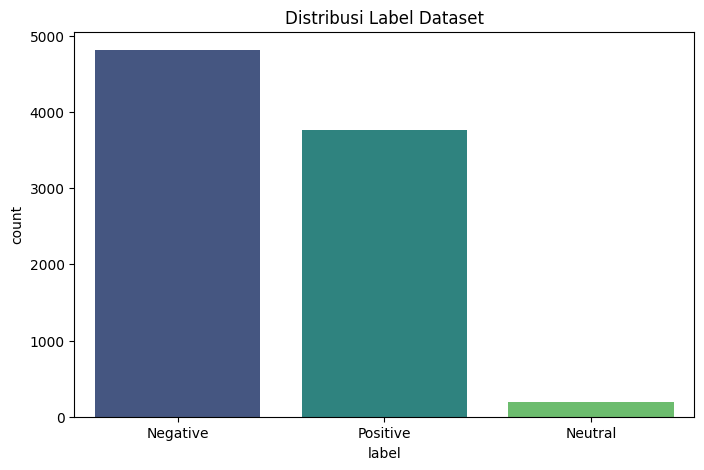

In [21]:
df = pd.read_csv('dataset_final_10000.csv')

print('=== DISTRIBUSI KELAS ===')
print(df['label'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', palette='viridis')
plt.title('Distribusi Label Dataset')
plt.show()

In [22]:
def display_wordcloud(sentiment_label, color='white'):
    text = ' '.join(review for review in df[df['label'] == sentiment_label].cleaned_content.astype(str))
    wc = WordCloud(width=800, height=400, background_color=color).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(f'Word Cloud - Sentimen {sentiment_label}', fontsize=15)
    plt.axis('off')
    plt.show()

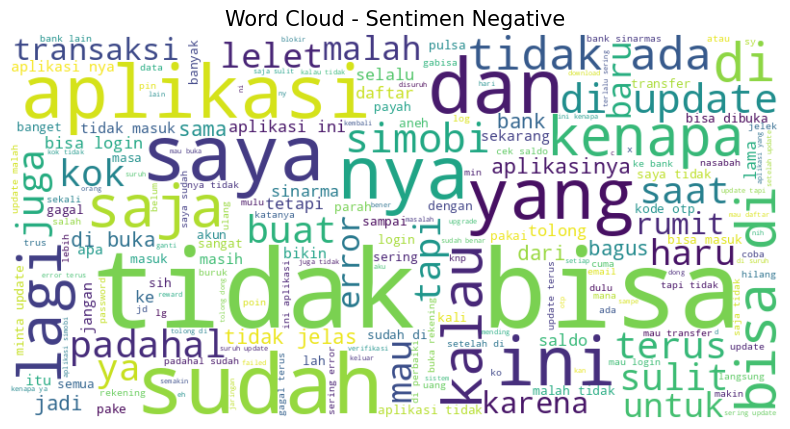

In [32]:
display_wordcloud('Negative')

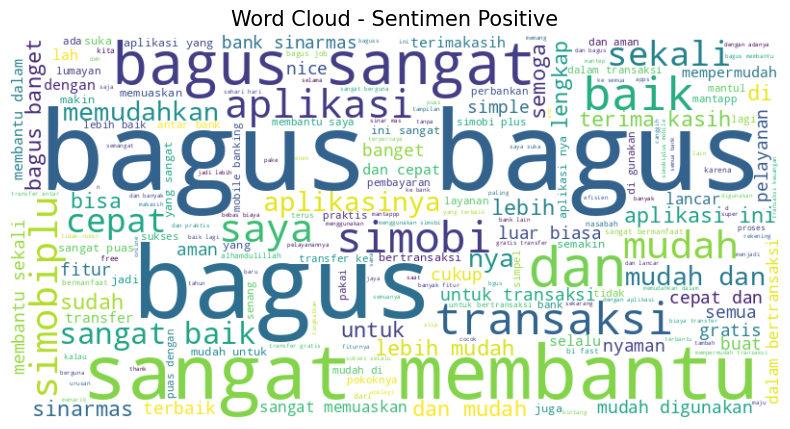

In [23]:
display_wordcloud('Positive')

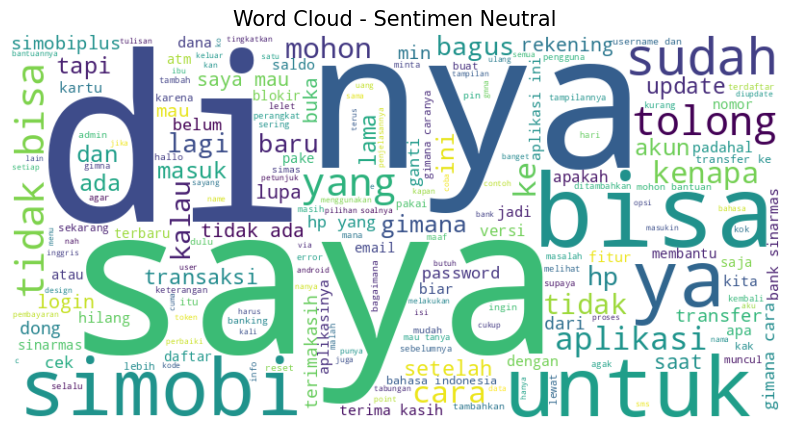

In [24]:
display_wordcloud('Neutral')

## 3. Eksperimen Model
Bagian ini berisi implementasi dari tiga skema pemodelan yang berbeda.

### Skema 1: SVM + TF-IDF ( 80:20 )

In [25]:
X_train_s1, X_test_s1, y_train_s1, y_test_s1 = train_test_split(
    df['cleaned_content'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train_s1)
X_test_tfidf = tfidf.transform(X_test_s1)

model_svm = SVC(kernel='linear', probability=True)
model_svm.fit(X_train_tfidf, y_train_s1)

y_pred_svm = model_svm.predict(X_test_tfidf)
print(f'Testing Accuracy SVM: {accuracy_score(y_test_s1, y_pred_svm)*100:.2f}%')

Testing Accuracy SVM: 97.15%


### Skema 2: Bi-LSTM + Embedding ( 80:20 )

In [26]:
y_encoded = pd.get_dummies(df['label']).values
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(
    df['cleaned_content'].astype(str), y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

max_words, max_len = 10000, 100
tokenizer_lstm = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer_lstm.fit_on_texts(X_train_s2)

X_train_pad = pad_sequences(tokenizer_lstm.texts_to_sequences(X_train_s2), maxlen=max_len, padding='post')
X_test_pad = pad_sequences(tokenizer_lstm.texts_to_sequences(X_test_s2), maxlen=max_len, padding='post')

model_lstm = Sequential([
    Embedding(max_words, 128),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

model_lstm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_lstm.fit(X_train_pad, y_train_s2, epochs=5, batch_size=32, validation_data=(X_test_pad, y_test_s2), verbose=0)

_, acc_lstm = model_lstm.evaluate(X_test_pad, y_test_s2, verbose=0)
print(f'Testing Accuracy Bi-LSTM: {acc_lstm*100:.2f}%')

Testing Accuracy Bi-LSTM: 97.03%


### Skema 3: IndoBERT Fine-Tuning ( 70:30 )

In [27]:
label_map = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
id2label = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
label2id = {'Negative': 0, 'Neutral': 1, 'Positive': 2}

df['label_num'] = df['label'].map(label_map)
train_s3, test_s3 = train_test_split(df, test_size=0.3, random_state=42, stratify=df['label_num'])

tokenizer_bert = AutoTokenizer.from_pretrained('indobenchmark/indobert-base-p1')

def tokenize_fn(batch):
    return tokenizer_bert(batch['cleaned_content'], padding='max_length', truncation=True, max_length=128)

train_ds = Dataset.from_pandas(train_s3.reset_index(drop=True)).map(tokenize_fn, batched=True, remove_columns=['cleaned_content', 'label', 'label_num'])
test_ds = Dataset.from_pandas(test_s3.reset_index(drop=True)).map(tokenize_fn, batched=True, remove_columns=['cleaned_content', 'label', 'label_num'])

train_ds = train_ds.add_column('labels', train_s3['label_num'].tolist())
test_ds = test_ds.add_column('labels', test_s3['label_num'].tolist())

model_bert = AutoModelForSequenceClassification.from_pretrained(
    'indobenchmark/indobert-base-p1', num_labels=3, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True
).to(device)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return {'accuracy': accuracy_score(labels, np.argmax(logits, axis=1))}

args = TrainingArguments(output_dir='./results', num_train_epochs=3, per_device_train_batch_size=16, eval_strategy='epoch', save_strategy='epoch', load_best_model_at_end=True)
trainer = Trainer(model=model_bert, args=args, train_dataset=train_ds, eval_dataset=test_ds, compute_metrics=compute_metrics)

trainer.train()
trainer.save_model('./saved_final_indobert')
tokenizer_bert.save_pretrained('./saved_final_indobert')

Map:   0%|          | 0/6135 [00:00<?, ? examples/s]

Map:   0%|          | 0/2630 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./saved_final_indobert/tokenizer_config.json',
 './saved_final_indobert/tokenizer.json')

## 4. Evaluasi dan Komparasi Model
Membandingkan akurasi dari ketiga model yang telah dilatih.

Training Loss,Validation Loss,Epoch,Accuracy
0.040228,0.072781,3,0.984411


,Model,Accuracy (%)
0,SVM + TF-IDF,97.147747
1,Bi-LSTM,97.033656
2,IndoBERT,98.441065


/tmp/ipykernel_2916/4227260287.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comparison_df, x='Model', y='Accuracy (%)', palette='magma')


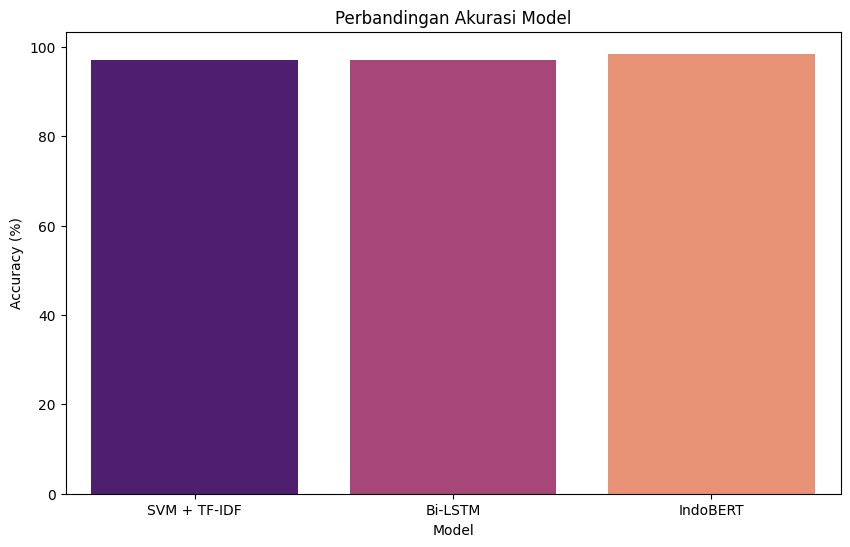

In [28]:
bert_acc = trainer.evaluate()['eval_accuracy']

results = {
    'Model': ['SVM + TF-IDF', 'Bi-LSTM', 'IndoBERT'],
    'Accuracy (%)': [accuracy_score(y_test_s1, y_pred_svm)*100, acc_lstm*100, bert_acc*100]
}

comparison_df = pd.DataFrame(results)
display(comparison_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=comparison_df, x='Model', y='Accuracy (%)', palette='magma')
plt.title('Perbandingan Akurasi Model')
plt.show()

## 5. Analisis Detail: Confusion Matrix & Classification Report
Evaluasi mendalam untuk melihat bagaimana setiap model memprediksi masing-masing kelas sentimen.

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Neutral', 'Positive']).plot(ax=ax, cmap='Blues')
    plt.title(f'Confusion Matrix - {title}')
    plt.show()

--- EVALUASI SVM ---
              precision    recall  f1-score   support

    Negative       0.96      0.99      0.98       963
     Neutral       1.00      0.05      0.10        38
    Positive       0.99      0.99      0.99       752

    accuracy                           0.97      1753
   macro avg       0.98      0.68      0.69      1753
weighted avg       0.97      0.97      0.96      1753



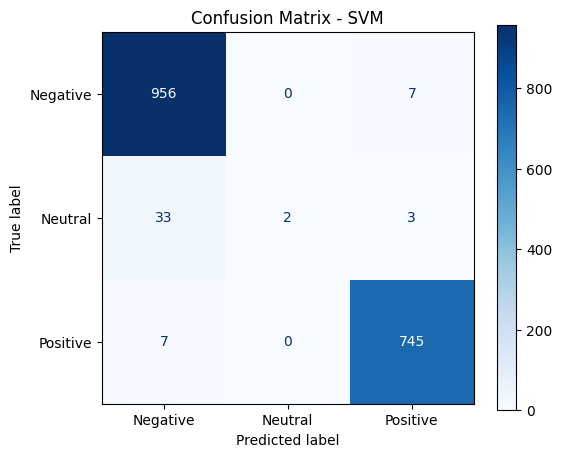

In [34]:
print('--- EVALUASI SVM ---')
print(classification_report(y_test_s1, y_pred_svm))
plot_cm(y_test_s1, y_pred_svm, 'SVM')

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

--- EVALUASI BI-LSTM ---
              precision    recall  f1-score   support

    Negative       0.96      0.99      0.97       963
     Neutral       0.67      0.26      0.38        38
    Positive       0.99      0.99      0.99       752

    accuracy                           0.97      1753
   macro avg       0.87      0.75      0.78      1753
weighted avg       0.97      0.97      0.97      1753



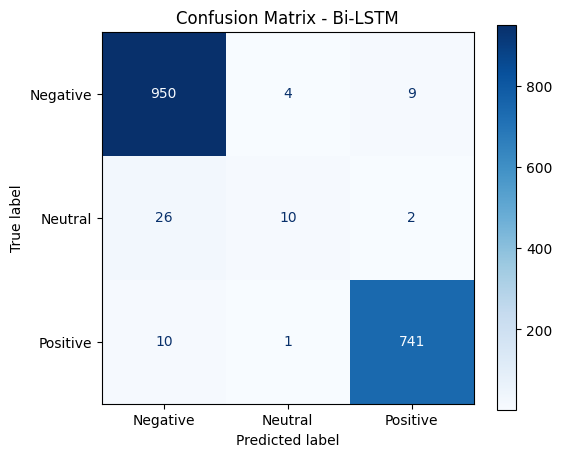

In [35]:
y_pred_lstm_raw = model_lstm.predict(X_test_pad)
y_pred_lstm = np.argmax(y_pred_lstm_raw, axis=1)
y_true_lstm = np.argmax(y_test_s2, axis=1)
print('\n--- EVALUASI BI-LSTM ---')
print(classification_report(y_true_lstm, y_pred_lstm, target_names=['Negative', 'Neutral', 'Positive']))
plot_cm(y_true_lstm, y_pred_lstm, 'Bi-LSTM')


--- EVALUASI INDOBERT ---
              precision    recall  f1-score   support

    Negative       0.99      0.99      0.99      1444
     Neutral       0.89      0.72      0.80        58
    Positive       0.99      1.00      1.00      1128

    accuracy                           0.99      2630
   macro avg       0.96      0.91      0.93      2630
weighted avg       0.99      0.99      0.99      2630



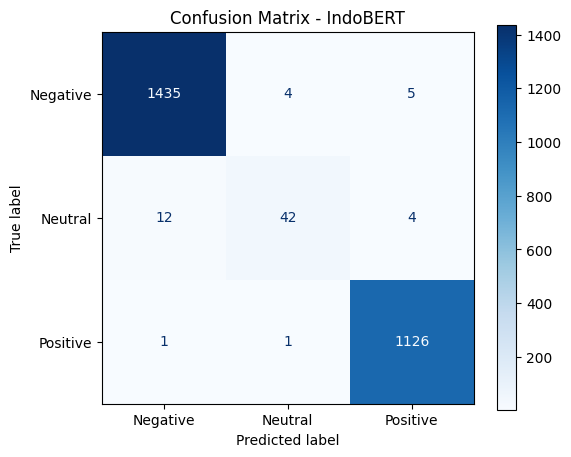

In [36]:
bert_preds_raw = trainer_s3.predict(test_ds)
bert_preds = np.argmax(bert_preds_raw.predictions, axis=1)
print('\n--- EVALUASI INDOBERT ---')
print(classification_report(test_ds['labels'], bert_preds, target_names=['Negative', 'Neutral', 'Positive']))
plot_cm(test_ds['labels'], bert_preds, 'IndoBERT')

## 6. Final Inference Testing
Menggunakan model IndoBERT yang telah dilatih untuk memprediksi ulasan baru secara real-time.

In [38]:
def prediksi_sentimen(teks):
    path = os.path.abspath('saved_final_indobert')
    model = AutoModelForSequenceClassification.from_pretrained(path).to(device)
    tokenizer = AutoTokenizer.from_pretrained(path)

    inputs = tokenizer(teks, return_tensors='pt', padding=True, truncation=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = model(**inputs)

    label_idx = torch.argmax(outputs.logits, dim=1).item()
    labels = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
    return labels[label_idx]

contoh_ulasan = [
    "Puas sekali menggunakan simobi plus,bebas biaya admin bulanan, transaksi lancar,gratis transfer ke semua bank, gratis tarik tunai di semua ATM. Pokoknya gak nyesal pakai Simobi plus bank Sinarmas. (*Saya pakai rekening Simas digi).",
    "Kenapa SimasTara yang sudah terkumpul 2,5jt, hanya bisa dicairkan 500rb... Saya minta tolong penjelasan di aplikasi SiMoBi.. Masalah ini terjadi setelah update terakhir aplikasi SiMoBi. Terimakasih",
]

for teks in contoh_ulasan:
    hasil = prediksi_sentimen(teks)
    print(f'Ulasan: "{teks}" -> Sentimen: {hasil}')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Ulasan: "Puas sekali menggunakan simobi plus,bebas biaya admin bulanan, transaksi lancar,gratis transfer ke semua bank, gratis tarik tunai di semua ATM. Pokoknya gak nyesal pakai Simobi plus bank Sinarmas. (*Saya pakai rekening Simas digi)." -> Sentimen: Positive


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Ulasan: "Kenapa SimasTara yang sudah terkumpul 2,5jt, hanya bisa dicairkan 500rb... Saya minta tolong penjelasan di aplikasi SiMoBi.. Masalah ini terjadi setelah update terakhir aplikasi SiMoBi. Terimakasih" -> Sentimen: Negative


## 7. Download File Output
Bagian ini digunakan untuk mengompres folder model dan mengunduh semua file penting (Dataset & Model) ke perangkat lokal.

In [31]:
import shutil
from google.colab import files

shutil.make_archive('model_indobert_final', 'zip', 'saved_final_indobert')

files_to_download = 'model_indobert_final.zip',

for file_path in files_to_download:
    if os.path.exists(file_path):
        print(f'Mengunduh: {file_path}')
        files.download(file_path)
    else:
        print(f'Peringatan: {file_path} tidak ditemukan.')

Mengunduh: model_indobert_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>